# AD vs FTD, Experiment 8: a pre-registered test of the aperiodic (1/f) EEG component

**Why this test.** The 11 experiments in `ADvsFTD_ds004504.ipynb` found no
feature set that separates Alzheimer's disease (AD, 36) from frontotemporal
dementia (FTD, 23) above chance. One published lead was left untested:

- **The claim.** Wang et al. (2023, *GeroScience* 46:751) reported, on this same
  cohort, that the **aperiodic exponent and offset** are higher in AD than in FTD.
  These are the slope and height of the EEG spectrum's 1/f background.
- **Why it is untested.** Their classifier applied SMOTE to all subjects *before*
  the train/test split, so synthetic copies of test subjects were in training. Its
  best single-feature AUC was 0.66.
- **This notebook** tests the claim once, honestly.

### Pre-registration

Written on 2026-11-10, before any aperiodic value of any subject was computed.
Cell 1 saves the protocol to `results/aperiodic/protocol.json` before any EEG is
read.

| | hypothesis (direction from Wang et al.) | one score per subject | blind? |
|---|---|---|---|
| **H1** | aperiodic **exponent** is higher in AD than in FTD | mean of the channel exponents | yes: never computed in this project |
| **H2** | aperiodic **offset** is higher in AD than in FTD | mean of the channel offsets | yes |
| **H3** | **theta/alpha ratio** is higher in AD than in FTD | mean over the 19 channels of log10(theta / alpha power) | partly: theta and alpha band power were already compared by diagnosis in `results/univariate.csv` |

- **Test.** Each score is used as it is, with the sign set by the hypothesis.
  Nothing is fitted, so there is nothing to cross-validate and nothing can leak.
  - Statistic: AUC = P(an AD subject scores higher than an FTD subject); 0.5 means
    no difference.
  - p-value: one-sided permutation test, 10,000 shuffles of the 59 diagnoses.
  - Correction: Holm over H1–H3. A hypothesis is **supported if its Holm p < 0.05**.
  - Uncertainty: 95 % CI from 2,000 stratified subject bootstraps.
- **Secondary analyses, also fixed now.** They are read as context and not corrected.
  1. **Severity and sex.** Does a score still predict the diagnosis once MMSE, age
     and sex are known? A likelihood-ratio test answers this. The AD patients here
     are more advanced (MMSE 17.8 vs 22.2), and Wang et al. found the exponent
     tracks MMSE.
  2. **What it means for one patient.** The project's classifier is trained on the
     three scores together and tested over subjects (20 × 5-fold), against a
     label-shuffle null.
  3. **Positive controls.** AD vs healthy controls (expected: higher in AD), and FTD
     vs healthy controls (Wang et al.: no difference).
  4. **Sensitivity.** Rerun without the fit-quality filter, and report every channel
     separately (descriptive).
  5. **A corrected spectrum.** Repeat H1–H2 with 2 s Hann windows, which recover a
     known exponent exactly. *Amendment, made on the same day and still before
     any subject's EEG was read.* The Cell 2 self-test showed that Wang et al.'s
     0.5 s window overestimates steep exponents (1/f^1.5 → 1.73), because power
     below 2 Hz leaks into the fit range. H1–H3 keep their settings, since their
     claim is what is under test.
- **Power, computed beforehand.** With 23 FTD subjects, a true AUC of 0.65 is
  detected about half the time. A null result is therefore weak evidence of no
  effect. **The result is reported whatever it is.**

### Method: Wang et al.'s own settings
Taken from their code, github.com/dcgggg/ds004504_Aperdiodic.

| | Wang et al. 2023 | here |
|---|---|---|
| data | 3 min, starting at minute 2 | the first 75 four-second epochs with no ASR join (300 s), as in Experiments 0–7 |
| reference | common average | common average |
| spectrum | Welch: Hamming window of 250 samples, overlap 125, nfft 1024 | the same, per epoch, averaged over the 75 epochs |
| FOOOF | `fixed` mode, 2–40 Hz, peak width 1–12 Hz, peak threshold 1, minimum height 0, no cap on peaks | the same (`fooof` 1.1.1) |
| fit filter | R² > 0.95 | a channel's exponent and offset count only if its fit has R² ≥ 0.95 |
| bands | theta 4–8 Hz, alpha 8–12 Hz | the same |

Run from top to bottom from `experiments_ad_vs_ftd/`. It takes about 2 minutes
and needs the dataset in `../data/`, the table `features/subjects.csv`, and the
`fooof` package (in `../requirements.txt`).

In [1]:
# ===========================================================================
# CELL 1 — IMPORTS, CONFIGURATION, AND THE PROTOCOL (saved before any EEG is read)
# ===========================================================================
import json, os, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from matplotlib.colors import LinearSegmentedColormap
from scipy import optimize, signal, stats
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
mne.set_log_level("ERROR")
with warnings.catch_warnings(record=True):         # fooof 1.1 announces its rename to specparam on import and
    import fooof                                   # switches warnings to "always"; record=True swallows both

EXP_DIR    = Path.cwd()                            # experiments_ad_vs_ftd/
PROJECT    = EXP_DIR.parent
DATA_ROOT  = PROJECT / "data"                      # ds004504 with derivatives/
FEAT_DIR   = EXP_DIR / "features"                  # subjects.csv: diagnosis, age, sex, MMSE
RESULT_DIR = EXP_DIR / "results" / "aperiodic"
assert (DATA_ROOT / "participants.tsv").exists(), \
    f"no dataset at {DATA_ROOT}: open this notebook from experiments_ad_vs_ftd/"
assert (FEAT_DIR / "subjects.csv").exists(), "no features/subjects.csv: run features_ad_ftd.ipynb first"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# ---- the data: the same 300 s per subject as features_ad_ftd.ipynb ----------------
SFREQ, EPOCH_S, N_EPOCHS = 500.0, 4.0, 75
EPOCH_N  = int(EPOCH_S * SFREQ)
CHANNELS = ["Fp1", "Fp2", "F3", "F4", "C3", "C4", "P3", "P4", "O1", "O2",
            "F7", "F8", "T3", "T4", "T5", "T6", "Fz", "Cz", "Pz"]

# ---- spectrum and FOOOF: Wang et al.'s settings, from their code --------------------
WELCH = dict(window="hamming", nperseg=250, noverlap=125, nfft=1024, detrend=False)  # pwelch(x, hamming(250), 125, 1024)
WELCH_2S = dict(window="hann", nperseg=1000, noverlap=500, nfft=1000, detrend=False)  # S5: features_ad_ftd.ipynb's 2 s windows
FOOOF_SETTINGS = dict(peak_width_limits=[1, 12], max_n_peaks=np.inf, min_peak_height=0.0,
                      peak_threshold=1.0, aperiodic_mode="fixed", verbose=False)
FIT_RANGE    = [2, 40]
MIN_R2       = 0.95
THETA, ALPHA = (4.0, 8.0), (8.0, 12.0)

# ---- statistics ------------------------------------------------------------------
SEED, N_BOOT, N_PERM, ALPHA_LEVEL = 42, 2000, 10000, 0.05
N_FOLDS, N_REPEATS, C_LR = 5, 20, 0.1              # the classifier and folds of ADvsFTD_ds004504.ipynb
N_NULL = 500                                       # label shuffles for the classifier's chance level (S2)
N_JOBS = max(1, min(8, (os.cpu_count() or 2) - 2))

HYPOTHESES = {"H1 exponent": "exponent", "H2 offset": "offset", "H3 theta/alpha ratio": "tar"}
WANG_CHANNELS = ["F3", "F4", "T3", "C3", "P3", "Pz"]  # where Wang et al. found exponent and offset higher in AD

PROTOCOL = {
    "written": "2026-11-10, before any aperiodic value of any subject was computed",
    "hypotheses_from": "Wang Z et al. (2023) GeroScience 46:751-768, doi:10.1007/s11357-023-01041-8 (same ds004504 cohort)",
    "subjects": "36 AD vs 23 FTD; healthy controls only in the positive controls (S3)",
    "data": f"first {N_EPOCHS} join-free {EPOCH_S:g} s epochs per subject (300 s), common average reference",
    "spectrum": "Welch per epoch (Hamming 250 samples, overlap 125, nfft 1024), mean over the epochs",
    "fooof": {**FOOOF_SETTINGS, "max_n_peaks": "inf", "freq_range": FIT_RANGE, "package": "fooof 1.1.1"},
    "fit_filter": f"a channel's exponent and offset enter the subject's mean only if R^2 >= {MIN_R2}; "
                  "a subject with no such channel is left out of H1/H2 and reported",
    "primary": {
        "H1": "mean aperiodic exponent over channels is higher in AD than in FTD",
        "H2": "mean aperiodic offset over channels is higher in AD than in FTD",
        "H3": f"mean over the 19 channels of log10(theta {THETA[0]:g}-{THETA[1]:g} Hz / alpha {ALPHA[0]:g}-{ALPHA[1]:g} Hz "
              "absolute power) is higher in AD than in FTD. Not blind: theta and alpha band power were already "
              "compared by diagnosis in results/univariate.csv"},
    "test": f"AUC = P(AD score > FTD score), the score used as is (nothing fitted); one-sided permutation p from "
            f"{N_PERM} shuffles of the 59 diagnoses; Holm over H1-H3; supported if Holm p < {ALPHA_LEVEL}; "
            f"95 % CI from {N_BOOT} stratified subject bootstraps",
    "secondary": [
        "S1: likelihood-ratio test for each score added to an unpenalised logistic model of MMSE + age + sex",
        f"S2: L2 logistic regression (C = {C_LR}, balanced) on H1-H3 together, {N_REPEATS} x {N_FOLDS}-fold CV over "
        f"subjects, with the folds of ADvsFTD_ds004504.ipynb, against {N_NULL} label shuffles",
        "S3: positive controls AD vs HC (expected higher in AD) and FTD vs HC (Wang et al.: no difference)",
        "S4: sensitivity without the R^2 filter, and each channel separately (descriptive)",
        "S5: H1-H2 again with 2 s Hann windows (50 % overlap), which recover a known exponent exactly"],
    "amendment": "2026-11-10, still before any subject's EEG was read: the Cell 2 self-test showed that Wang et al.'s "
                 "0.5 s window overestimates steep exponents (1/f^1.5 -> 1.73, 1/f^2 -> 2.48), because power below "
                 "2 Hz leaks into the fit range; S5 was added. H1-H3 keep Wang et al.'s settings, since they are "
                 "the claim under test",
    "decision": "the result is reported whatever it is",
}
(RESULT_DIR / "protocol.json").write_text(json.dumps(PROTOCOL, indent=1, ensure_ascii=False) + "\n", encoding="utf-8")

# ---- figures: the dataviz reference palette, as in ADvsFTD_ds004504.ipynb -----------
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]                    # categorical slots 1-3, in this order
GROUP_COLOR = {"AD": SERIES[0], "FTD": SERIES[1], "HC": SERIES[2]}
DIVERGING = LinearSegmentedColormap.from_list(                # blue = higher in AD, red = higher in FTD
    "ad_ftd", ["#184f95", "#6da7ec", "#f0efec", "#ec8a89", "#b52e2e"])
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9, "legend.frameon": False, "lines.linewidth": 2})
print(f"data     : {DATA_ROOT}\nresults  : {RESULT_DIR}\nworkers  : {N_JOBS}\nfooof    : {fooof.__version__}")
print(f"protocol : written to {(RESULT_DIR / 'protocol.json').relative_to(EXP_DIR)} before any EEG was read")

data     : C:\Projects\Major Project\data
results  : C:\Projects\Major Project\experiments_ad_vs_ftd\results\aperiodic
workers  : 8
fooof    : 1.1.1
protocol : written to results\aperiodic\protocol.json before any EEG was read


---
## The measures and the statistics, each checked on a known answer (Cell 2)

The **aperiodic component** is the straight line that a resting EEG spectrum
follows in log-log axes, underneath its oscillatory peaks. FOOOF models
log10 P(f) as that line plus Gaussian peaks:

$$\log_{10} P(f) = b - \chi \log_{10} f + \sum_n G_n(f)$$

- $b$, the **offset**, is the line's height: overall broadband power.
- $\chi$, the **exponent**, is its steepness. A steeper spectrum is often read as
  a shift of the excitation–inhibition balance towards inhibition.

The cell stops the notebook if any check fails:
- White noise has exponent 0, a known offset, and a theta/alpha ratio of 0.
- Coloured noise with power ∝ 1/f^χ, plus a 10 Hz rhythm, gives back χ through
  the same Welch + FOOOF pipeline with 2 s windows.
- With Wang et al.'s 0.5 s windows, χ = 1 is recovered too. Steeper spectra come
  out too steep, and the cell prints by how much. A short window cannot
  separate 2 Hz from the large power just below it, and in dementia that power
  is delta.
- The AUC, permutation, Holm and logistic-regression code agrees with scikit-learn
  or with hand-computed answers.

In [2]:
# ===========================================================================
# CELL 2 — THE MEASURES AND THE STATISTICS, EACH CHECKED ON A KNOWN ANSWER
# ===========================================================================
def set_file(sid):
    return DATA_ROOT / "derivatives" / sid / "eeg" / f"{sid}_task-eyesclosed_eeg.set"


def clean_epochs(sid):
    """The first N_EPOCHS epochs of the 4 s grid with no ASR join ('boundary') inside, in µV:
    (75, 19, 2000). The same selection as features_ad_ftd.ipynb."""
    with warnings.catch_warnings():                       # parallel workers do not inherit Cell 1's filter
        warnings.filterwarnings("ignore")
        raw = mne.io.read_raw_eeglab(set_file(sid), preload=False, verbose="ERROR")
    joins = np.array([a["onset"] for a in raw.annotations if a["description"] == "boundary"]) * SFREQ
    starts = np.arange(0, raw.n_times - EPOCH_N + 1, EPOCH_N)
    inside = (joins[None, :] > starts[:, None]) & (joins[None, :] < starts[:, None] + EPOCH_N)
    starts = starts[~inside.any(axis=1)][:N_EPOCHS]
    assert len(starts) == N_EPOCHS, f"{sid}: fewer than {N_EPOCHS} clean epochs"
    x = raw.get_data(picks=CHANNELS, start=0, stop=int(starts[-1]) + EPOCH_N) * 1e6
    return np.stack([x[:, s:s + EPOCH_N] for s in starts])


def spectrum(ep, welch=WELCH):
    """Common average reference, then Welch per epoch and the mean over epochs: freqs (F,), psd (19, F) in µV²/Hz."""
    ep = ep - ep.mean(axis=1, keepdims=True)
    freqs, psd = signal.welch(ep, fs=SFREQ, axis=-1, **welch)
    return freqs, psd.mean(axis=0)


def band_power(freqs, psd, band):
    m = (freqs >= band[0]) & (freqs <= band[1])
    return np.trapezoid(psd[..., m], freqs[m], axis=-1)


def measures(freqs, psd):
    """One row per channel: FOOOF offset and exponent, the fit's R² and peak count, log10 theta/alpha power."""
    with warnings.catch_warnings(record=True):            # imported here, not globally, so that parallel
        from fooof import FOOOF                           # workers do not print fooof's rename notice
    rows = []
    for ch, p in zip(CHANNELS, psd):
        fm = FOOOF(**FOOOF_SETTINGS)
        fm.fit(freqs, p, FIT_RANGE)
        offset, exponent = fm.aperiodic_params_            # NaN, with R² NaN, if a fit fails
        rows.append(dict(channel=ch, offset=offset, exponent=exponent, r2=fm.r_squared_, n_peaks=fm.n_peaks_,
                         tar=np.log10(band_power(freqs, p, THETA) / band_power(freqs, p, ALPHA))))
    return pd.DataFrame(rows)


def auc_hi(score, hi):
    """P(a `hi` subject scores higher than another subject), ties counted half; subjects with no score left out."""
    score, hi = np.asarray(score, float), np.asarray(hi, bool)
    ok = np.isfinite(score)
    s, h = score[ok], hi[ok]
    return stats.mannwhitneyu(s[h], s[~h]).statistic / (h.sum() * (~h).sum())


def directional_test(score, hi, seed, n_perm=N_PERM):
    """auc_hi, its 95 % CI from a stratified subject bootstrap, and the one-sided permutation p
    for 'higher in hi'. The score is used as it is: nothing is fitted."""
    score, hi = np.asarray(score, float), np.asarray(hi, bool)
    ok = np.isfinite(score)
    s, h = score[ok], hi[ok]
    n1, n0 = int(h.sum()), int((~h).sum())
    to_auc = lambda rank_sum: (rank_sum - n1 * (n1 + 1) / 2) / (n1 * n0)
    rng = np.random.default_rng(seed)
    ranks = stats.rankdata(s)                                 # ties share their average rank
    auc = to_auc(ranks[h].sum())
    null = to_auc(np.array([rng.permutation(h) for _ in range(n_perm)]).astype(float) @ ranks)
    i1, i0 = np.where(h)[0], np.where(~h)[0]
    b = np.concatenate([i1[rng.integers(0, n1, (N_BOOT, n1))], i0[rng.integers(0, n0, (N_BOOT, n0))]], axis=1)
    boot = to_auc(stats.rankdata(s[b], axis=1)[:, :n1].sum(1))
    return dict(n_hi=n1, n_other=n0, n_left_out=int((~ok).sum()), auc=auc,
                ci_low=np.percentile(boot, 2.5), ci_high=np.percentile(boot, 97.5),
                p_one_sided=(1 + (null >= auc).sum()) / (n_perm + 1), auc_needed=np.percentile(null, 95))


def holm(p):
    """Holm-Bonferroni adjusted p-values, in the input order (as in ADvsFTD_ds004504.ipynb)."""
    p, out, run = np.asarray(p, float), np.empty(len(p)), 0.0
    for k, i in enumerate(np.argsort(p)):
        run = max(run, (len(p) - k) * p[i])
        out[i] = min(1.0, run)
    return out


def logit_loglik(X, yy):
    """Maximised log-likelihood and coefficients (intercept first) of an unpenalised logistic regression."""
    X = np.column_stack([np.ones(len(yy)), X])
    nll  = lambda b: np.logaddexp(0, X @ b).sum() - yy @ (X @ b)
    grad = lambda b: X.T @ (1 / (1 + np.exp(-(X @ b))) - yy)
    res = optimize.minimize(nll, np.zeros(X.shape[1]), jac=grad, method="BFGS", options=dict(gtol=1e-9))
    return -res.fun, res.x


# ---- known-answer tests ---------------------------------------------------------
rng = np.random.default_rng(0)
checks = []


def expect(what, value, lo, hi):
    checks.append((what, float(value), lo, hi, bool(lo <= value <= hi)))


def coloured_noise(chi, sine_uv=0.0):
    """(75, 19, 2000) µV: independent channels with power ∝ 1/f^chi (SD 10 µV), plus an optional 10 Hz sine."""
    n = N_EPOCHS * EPOCH_N
    f = np.fft.rfftfreq(n, 1 / SFREQ)
    amp = np.zeros_like(f)
    amp[1:] = f[1:] ** (-chi / 2)
    x = np.fft.irfft(amp * np.exp(2j * np.pi * rng.random((len(CHANNELS), len(f)))), n=n)
    x *= 10 / x.std(axis=1, keepdims=True)
    x += sine_uv * np.sin(2 * np.pi * 10 * np.arange(n) / SFREQ + 2 * np.pi * rng.random((len(CHANNELS), 1)))
    return x.reshape(len(CHANNELS), N_EPOCHS, EPOCH_N).transpose(1, 0, 2)


white = measures(*spectrum(coloured_noise(0.0)))
expect("white noise: exponent", white.exponent.mean(), -0.05, 0.05)
expect("white noise: offset = log10(2 var (18/19) / fs)", white.offset.mean() - np.log10(2 * 100 * 18 / 19 / SFREQ), -0.03, 0.03)
expect("white noise: log10 theta/alpha", white.tar.mean(), -0.03, 0.03)
BIAS = []                                                    # what each window makes of a known exponent
for chi in (1.0, 1.5, 2.0):
    ep = coloured_noise(chi, sine_uv=3.0)
    m2, mw = measures(*spectrum(ep, WELCH_2S)), measures(*spectrum(ep, WELCH))
    expect(f"1/f^{chi:g} + 10 Hz sine, 2 s windows: exponent", m2.exponent.mean(), chi - 0.05, chi + 0.05)
    expect(f"1/f^{chi:g} + 10 Hz sine, 2 s windows: R²", m2.r2.min(), MIN_R2, 1.0)
    BIAS.append(dict(true=chi, wang_0_5s=mw.exponent.mean(), hann_2s=m2.exponent.mean()))
expect("1/f^1 + 10 Hz sine, Wang's 0.5 s windows: exponent", BIAS[0]["wang_0_5s"], 0.9, 1.1)
ep = coloured_noise(1.5)
expect("common average reference: channels sum to 0", np.abs((ep - ep.mean(1, keepdims=True)).sum(1)).max(), 0, 1e-9)

s, h = rng.standard_normal(59), np.arange(59) < 36
expect("auc_hi = scikit-learn AUC", auc_hi(s, h) - roc_auc_score(h, s), -1e-12, 1e-12)
r = directional_test(s, h, 0, n_perm=2000)
expect("directional_test AUC = auc_hi", r["auc"] - auc_hi(s, h), -1e-12, 1e-12)
r = directional_test(h + 0.1 * s, h, 0, n_perm=2000)
expect("perfect separation: p = 1 / (shuffles + 1)", r["p_one_sided"] * 2001, 1 - 1e-9, 1 + 1e-9)
expect("Holm on (0.01, 0.04, 0.03)", np.abs(holm([0.01, 0.04, 0.03]) - [0.03, 0.06, 0.06]).max(), 0, 1e-12)
Xr = rng.standard_normal((200, 3))
yr = (Xr @ [1.0, -0.5, 0.0] + rng.logistic(size=200) > 0).astype(float)
_, b = logit_loglik(Xr, yr)
sk = LogisticRegression(C=1e12, max_iter=10000).fit(Xr, yr)
expect("logistic MLE = scikit-learn", np.abs(b - np.r_[sk.intercept_, sk.coef_[0]]).max(), 0, 1e-3)

print(f"{'check':52s}{'value':>11s}   expected")
for what, v, lo, hi, ok in checks:
    print(f"{what:52s}{v:11.4f}   {lo:g} to {hi:g}   {'ok' if ok else 'FAIL'}")
failed = [c[0] for c in checks if not c[4]]
assert not failed, f"known-answer test failed: {failed}"
print(f"\nall {len(checks)} checks pass")
print("\nexponent recovered from coloured noise of known slope (a measured property, not a check):")
print(pd.DataFrame(BIAS).to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("Wang et al.'s 0.5 s window lets power below 2 Hz leak into the fit range, which steepens steep spectra")
print("more than shallow ones. That is why S5 repeats H1-H2 with 2 s windows.")

check                                                     value   expected
white noise: exponent                                    0.0004   -0.05 to 0.05   ok
white noise: offset = log10(2 var (18/19) / fs)         -0.0035   -0.03 to 0.03   ok
white noise: log10 theta/alpha                          -0.0005   -0.03 to 0.03   ok
1/f^1 + 10 Hz sine, 2 s windows: exponent                1.0045   0.95 to 1.05   ok
1/f^1 + 10 Hz sine, 2 s windows: R²                      0.9933   0.95 to 1   ok
1/f^1.5 + 10 Hz sine, 2 s windows: exponent              1.4899   1.45 to 1.55   ok
1/f^1.5 + 10 Hz sine, 2 s windows: R²                    0.9904   0.95 to 1   ok
1/f^2 + 10 Hz sine, 2 s windows: exponent                1.9901   1.95 to 2.05   ok
1/f^2 + 10 Hz sine, 2 s windows: R²                      0.9796   0.95 to 1   ok
1/f^1 + 10 Hz sine, Wang's 0.5 s windows: exponent       1.0805   0.9 to 1.1   ok
common average reference: channels sum to 0              0.0000   0 to 1e-09   ok
auc_hi = sc

---
## Fits for all 88 subjects (Cell 3)

Each channel of each subject gets one spectrum: the mean over its 75 epochs.
FOOOF then fits that spectrum twice, once with Wang et al.'s 0.5 s windows
(H1–H3) and once with 2 s windows (S5). This cell does not read the
diagnosis. It reports only how well the fits went, and how the numbers compare
in scale with Wang et al.'s.

In [3]:
# ===========================================================================
# CELL 3 — SPECTRA AND FOOOF FITS FOR ALL 88 SUBJECTS  (the diagnosis is not read here)
# ===========================================================================
subj = pd.read_csv(FEAT_DIR / "subjects.csv", index_col=0)


def subject_fit(sid):
    ep = clean_epochs(sid)
    freqs, psd = spectrum(ep, WELCH)
    return (measures(freqs, psd).assign(participant_id=sid),
            measures(*spectrum(ep, WELCH_2S)).assign(participant_id=sid), freqs, psd)


t0 = time.time()
out = Parallel(n_jobs=N_JOBS)(delayed(subject_fit)(s) for s in subj.index)
FITS    = pd.concat([o[0] for o in out], ignore_index=True)       # Wang et al.'s windows: H1-H3
FITS_2S = pd.concat([o[1] for o in out], ignore_index=True)       # 2 s windows: S5
FREQS, PSD = out[0][2], np.stack([o[3] for o in out])             # (88, 19, F), for the figures
print(f"{len(FITS)} channels ({len(subj)} subjects x {len(CHANNELS)}), each fitted twice, in {time.time() - t0:.0f} s")


def subject_scores(fits, use):
    """Per subject: mean exponent and offset over the channels in `use`, and mean theta/alpha over all 19."""
    ap = fits[use].groupby("participant_id")[["exponent", "offset"]].mean()
    return pd.DataFrame({"exponent": ap.exponent, "offset": ap.offset,
                         "tar": fits.groupby("participant_id").tar.mean(),
                         "n_channels_fit": fits[use].groupby("participant_id").size()}).reindex(subj.index)


SCORES     = subject_scores(FITS, FITS.r2 >= MIN_R2)                  # primary
SCORES_ALL = subject_scores(FITS, np.ones(len(FITS), bool))           # S4: no fit filter
SCORES_2S  = subject_scores(FITS_2S, FITS_2S.r2 >= MIN_R2)            # S5: 2 s windows
for t in (SCORES, SCORES_ALL, SCORES_2S):
    t["n_channels_fit"] = t.n_channels_fit.fillna(0).astype(int)

print(f"\n{'fit quality':34s}{'0.5 s (Wang)':>14s}{'2 s':>10s}")
for label, f in [("median R²", lambda d: d.r2.median()), ("lowest R²", lambda d: d.r2.min()),
                 ("fits with R² < 0.95", lambda d: (~(d.r2 >= MIN_R2)).sum()),
                 ("subjects with such a fit", lambda d: d[~(d.r2 >= MIN_R2)].participant_id.nunique()),
                 ("median peaks per fit", lambda d: d.n_peaks.median())]:
    print(f"{label:34s}{f(FITS):14.3f}{f(FITS_2S):10.3f}")
print(f"subjects with no channel left     {(SCORES.n_channels_fit == 0).sum():14d}{(SCORES_2S.n_channels_fit == 0).sum():10d}")
bad = FITS[~(FITS.r2 >= MIN_R2)]
print(f"\nthe failing fits (0.5 s): median exponent {bad.exponent.median():.2f} vs {FITS[FITS.r2 >= MIN_R2].exponent.median():.2f} "
      f"for the rest; most at {', '.join(bad.channel.value_counts().index[:6])}; "
      f"{(bad.participant_id.value_counts() >= 10).sum()} subjects lose 10 or more of 19 channels")

q = lambda v: f"{np.nanmedian(v):.2f} [{np.nanpercentile(v, 25):.2f}, {np.nanpercentile(v, 75):.2f}]"
print(f"\nall 88 subjects, median [IQR]:  exponent {q(SCORES.exponent)}   offset {q(SCORES.offset)}   "
      f"log10 theta/alpha {q(SCORES.tar)}")
print(f"                  2 s windows:  exponent {q(SCORES_2S.exponent)}   offset {q(SCORES_2S.offset)}")
print("Wang et al.'s group means, for scale: exponent 1.06-1.31, offset 0.73-1.02")
print(f"exponent vs offset across subjects: Spearman rho {stats.spearmanr(SCORES.exponent, SCORES.offset, nan_policy='omit').statistic:.2f} "
      "(Wang et al.: 0.81-0.92 within groups)")
print(f"exponent, 0.5 s vs 2 s windows:   Spearman rho {stats.spearmanr(SCORES.exponent, SCORES_2S.exponent, nan_policy='omit').statistic:.2f}")

1672 channels (88 subjects x 19), each fitted twice, in 30 s

fit quality                         0.5 s (Wang)       2 s
median R²                                  0.987     0.989
lowest R²                                  0.000     0.084
fits with R² < 0.95                      381.000   307.000
subjects with such a fit                  64.000    61.000
median peaks per fit                       3.000     7.000
subjects with no channel left                  0         0

the failing fits (0.5 s): median exponent 0.71 vs 1.34 for the rest; most at T4, F7, Fp1, F3, F4, Fp2; 14 subjects lose 10 or more of 19 channels

all 88 subjects, median [IQR]:  exponent 1.27 [1.06, 1.51]   offset 0.88 [0.58, 1.10]   log10 theta/alpha -0.15 [-0.41, 0.24]
                  2 s windows:  exponent 1.15 [0.97, 1.38]   offset 0.66 [0.42, 0.93]
Wang et al.'s group means, for scale: exponent 1.06-1.31, offset 0.73-1.02
exponent vs offset across subjects: Spearman rho 0.89 (Wang et al.: 0.81-0.92 within group

---
## The pre-registered test (Cell 4)

Only the 59 patients enter this cell. For each hypothesis:
- The AUC is the share of AD–FTD pairs in which the AD patient has the higher score.
- The permutation p asks how often shuffled diagnoses give an AUC at least that high.
- `needed` is the AUC that a one-sided p < 0.05 would require, before Holm.

In [4]:
# ===========================================================================
# CELL 4 — THE PRE-REGISTERED TEST: H1-H3, 36 AD vs 23 FTD
# ===========================================================================
INFO  = subj[subj.group.isin(["AD", "FTD"])]
is_ad = (INFO.group == "AD").to_numpy()
S     = SCORES.loc[INFO.index]

rows = []
for k, (name, col) in enumerate(HYPOTHESES.items()):
    x = S[col].to_numpy()
    rows.append(dict(hypothesis=name, median_AD=np.nanmedian(x[is_ad]), median_FTD=np.nanmedian(x[~is_ad]),
                     **directional_test(x, is_ad, SEED + k)))
TESTS = pd.DataFrame(rows)
TESTS["p_holm"] = holm(TESTS.p_one_sided)
TESTS["supported"] = TESTS.p_holm < ALPHA_LEVEL

print(f"{is_ad.sum()} AD vs {(~is_ad).sum()} FTD.   AUC = P(AD score > FTD score); 0.5 = no difference\n")
print(f"{'hypothesis':24s}{'median AD':>11s}{'median FTD':>12s}{'AUC':>8s}{'95% CI':>18s}"
      f"{'p 1-sided':>11s}{'p Holm':>9s}{'needed':>8s}   verdict")
print("-" * 116)
for r in TESTS.itertuples():
    print(f"{r.hypothesis:24s}{r.median_AD:11.3f}{r.median_FTD:12.3f}{r.auc:8.3f}"
          f"{f'[{r.ci_low:.3f}, {r.ci_high:.3f}]':>18s}{r.p_one_sided:11.4f}{r.p_holm:9.4f}{r.auc_needed:8.3f}   "
          f"{'SUPPORTED' if r.supported else 'not supported'}")
print(f"\nsubjects left out for lack of a fit with R² >= {MIN_R2}: {TESTS.n_left_out.tolist()}")

36 AD vs 23 FTD.   AUC = P(AD score > FTD score); 0.5 = no difference

hypothesis                median AD  median FTD     AUC            95% CI  p 1-sided   p Holm  needed   verdict
--------------------------------------------------------------------------------------------------------------------
H1 exponent                   1.425       1.207   0.632    [0.481, 0.779]     0.0479   0.0879   0.629   not supported
H2 offset                     0.978       0.703   0.640    [0.482, 0.785]     0.0360   0.0879   0.628   not supported
H3 theta/alpha ratio          0.219      -0.016   0.644    [0.498, 0.785]     0.0293   0.0879   0.624   not supported

subjects left out for lack of a fit with R² >= 0.95: [0, 0, 0]


---
## Secondary analyses (Cells 5–6)

These were fixed in the protocol too. They are context, not extra chances to
find an effect, so they are not corrected.

- **S1, severity.** The AD patients here are more impaired than the FTD patients,
  and slowing tracks severity. A score that only measures severity would
  "separate" the groups without saying anything about which disease it is. MMSE
  is part of the diagnostic work-up, so no classifier in this project uses it.
  Here it is a covariate only.
- **S3, positive controls.** If the method works, AD vs healthy controls should
  show the effect.
- **S4–S5, robustness.** The test again without the fit filter, then with
  unbiased 2 s windows. The last table lists every channel, with Wang et al.'s
  six marked `*`.
- **S6, muscle: post hoc.** This check was added after Cell 3 showed that the
  failing fits are flat spectra, mostly at frontal and temporal electrodes, and
  that they cluster in a few subjects. That is what muscle activity looks like.
  Muscle activity flattens the spectrum and lowers the exponent, so it could
  fake H1.
- **S2, one patient at a time (Cell 6).** What the scores are worth to a
  classifier that never sees the test patient.

In [5]:
# ===========================================================================
# CELL 5 — SECONDARY: SEVERITY (S1), POSITIVE CONTROLS (S3), ROBUSTNESS (S4, S5), MUSCLE (S6, post hoc)
# ===========================================================================
z = lambda v: (v - v.mean()) / v.std()
y_ad = is_ad.astype(float)
base = np.column_stack([z(INFO.mmse.to_numpy(float)), z(INFO.age.to_numpy(float)), (INFO.sex == "M").to_numpy(float)])


def added_value(covariates, x):
    """Coefficient per SD of x, LR chi², and p, when x is added to a logistic model of AD vs FTD on the covariates."""
    ok = np.isfinite(x)
    ll0, _ = logit_loglik(covariates[ok], y_ad[ok])
    ll1, b = logit_loglik(np.column_stack([covariates[ok], z(x[ok])]), y_ad[ok])
    return dict(coef_per_sd=b[-1], lr_stat=2 * (ll1 - ll0), p_lr=stats.chi2.sf(2 * (ll1 - ll0), 1))


# S1: does each score still predict AD once MMSE, age and sex are known?
rows = []
for name, col in HYPOTHESES.items():
    x = S[col].to_numpy()
    ok = np.isfinite(x)
    rows.append(dict(hypothesis=name, **added_value(base, x),
                     rho_mmse_AD=stats.spearmanr(x[is_ad & ok], INFO.mmse[is_ad & ok]).statistic,
                     rho_mmse_FTD=stats.spearmanr(x[~is_ad & ok], INFO.mmse[~is_ad & ok]).statistic))
ADJUSTED = pd.DataFrame(rows)
print("S1  each score added to a logistic model of AD vs FTD on MMSE + age + sex")
print(f"{'hypothesis':24s}{'coef / SD':>10s}{'LR chi2':>9s}{'p':>8s}{'rho with MMSE: AD':>20s}{'FTD':>7s}")
for r in ADJUSTED.itertuples():
    print(f"{r.hypothesis:24s}{r.coef_per_sd:+10.2f}{r.lr_stat:9.2f}{r.p_lr:8.3f}{r.rho_mmse_AD:+20.2f}{r.rho_mmse_FTD:+7.2f}")
print("coef > 0: a higher score makes AD more likely at the same MMSE, age and sex")

# S3: positive controls against healthy controls
rows = []
for k, (name, col) in enumerate(HYPOTHESES.items()):
    for j, (a, b_) in enumerate([("AD", "HC"), ("FTD", "HC")]):
        sub = subj[subj.group.isin([a, b_])]
        rows.append(dict(hypothesis=name, comparison=f"{a} > {b_}",
                         **directional_test(SCORES.loc[sub.index, col].to_numpy(), (sub.group == a).to_numpy(),
                                            SEED + 10 + 2 * k + j)))
CONTROLS = pd.DataFrame(rows)
print("\nS3  positive controls: AUC = P(patient score > healthy-control score)")
print(f"{'hypothesis':24s}{'comparison':>12s}{'AUC':>8s}{'95% CI':>18s}{'p 1-sided':>11s}")
for r in CONTROLS.itertuples():
    print(f"{r.hypothesis:24s}{r.comparison:>12s}{r.auc:8.3f}{f'[{r.ci_low:.3f}, {r.ci_high:.3f}]':>18s}{r.p_one_sided:11.4f}")

# S4 and S5: the test again, without the fit filter and with 2 s windows
rows = []
for k, (name, col) in enumerate(list(HYPOTHESES.items())[:2]):
    for j, (label, table) in enumerate([("no R² filter", SCORES_ALL), ("2 s windows", SCORES_2S)]):
        rows.append(dict(hypothesis=name, variant=label,
                         **directional_test(table.loc[INFO.index, col].to_numpy(), is_ad, SEED + 20 + 2 * k + j)))
ROBUST = pd.DataFrame(rows)
print("\nS4-S5  H1-H2 again, AD vs FTD")
print(f"{'hypothesis':24s}{'variant':>14s}{'AUC':>8s}{'95% CI':>18s}{'p 1-sided':>11s}")
for r in ROBUST.itertuples():
    print(f"{r.hypothesis:24s}{r.variant:>14s}{r.auc:8.3f}{f'[{r.ci_low:.3f}, {r.ci_high:.3f}]':>18s}{r.p_one_sided:11.4f}")

# S6, POST HOC: added after Cell 3 showed that the fits failing R² >= 0.95 are flat spectra, mostly at
# frontal and temporal electrodes, and cluster in a few subjects. That is the signature of muscle
# activity, which flattens the spectrum above ~20 Hz and so lowers the exponent. If one group had more
# of it, H1 could be "supported" by muscle rather than by the brain. Descriptive only.
n_bad = (~(FITS.r2 >= MIN_R2)).groupby(FITS.participant_id).sum().reindex(INFO.index).to_numpy()
hf = (FREQS >= 30) & (FREQS <= 40)
emg = np.log10(PSD[:, :, hf].mean(-1)).mean(-1)[subj.index.get_indexer(INFO.index)]
clean = n_bad <= 9                                                   # at least 10 of 19 channels fitted well
rows = []
for k, (name, col) in enumerate(list(HYPOTHESES.items())[:2]):
    x = S[col].to_numpy()
    rows.append(dict(hypothesis=name, variant="subjects with >= 10 good fits",
                     **directional_test(x[clean], is_ad[clean], SEED + 30 + k)))
    rows.append(dict(hypothesis=name, variant="adjusted for 30-40 Hz power",
                     **added_value(np.column_stack([base, z(emg)]), x)))
MUSCLE = pd.DataFrame(rows)
print("\nS6 (post hoc)  muscle activity, AD vs FTD;  AUC = P(AD > FTD)")
print(f"    channels failing R² >= {MIN_R2} per subject: median AD {np.median(n_bad[is_ad]):.0f}, "
      f"FTD {np.median(n_bad[~is_ad]):.0f};  AUC {auc_hi(n_bad, is_ad):.3f}")
print(f"    log10 power 30-40 Hz, mean of 19 channels:  median AD {np.median(emg[is_ad]):.3f}, "
      f"FTD {np.median(emg[~is_ad]):.3f};  AUC {auc_hi(emg, is_ad):.3f}")
for r in MUSCLE.itertuples():
    if r.variant.startswith("subjects"):
        print(f"    {r.hypothesis:12s} {r.variant:30s} ({r.n_hi} AD, {r.n_other} FTD): AUC {r.auc:.3f} "
              f"[{r.ci_low:.3f}, {r.ci_high:.3f}], p 1-sided {r.p_one_sided:.4f}")
    else:
        print(f"    {r.hypothesis:12s} {r.variant:30s} (with MMSE, age, sex): coef / SD {r.coef_per_sd:+.2f}, p {r.p_lr:.3f}")

# S4: every channel separately (descriptive: 57 uncorrected AUCs)
pc = FITS.merge(subj[["group"]], left_on="participant_id", right_index=True)
pc = pc[pc.group.isin(["AD", "FTD"])].copy()
pc.loc[~(pc.r2 >= MIN_R2), ["exponent", "offset"]] = np.nan
PER_CHANNEL = pd.DataFrame([dict(channel=ch, **{col: auc_hi(g[col].to_numpy(), (g.group == "AD").to_numpy())
                                                for col in HYPOTHESES.values()})
                            for ch, g in pc.groupby("channel", sort=False)])
print("\nS4  per channel, AUC = P(AD > FTD)   (* = where Wang et al. found exponent and offset higher in AD)")
print("channel  " + "".join(f"{c + ('*' if c in WANG_CHANNELS else ''):>6s}" for c in PER_CHANNEL.channel))
for col in HYPOTHESES.values():
    print(f"{col:9s}" + "".join(f"{v:6.2f}" for v in PER_CHANNEL[col]))

S1  each score added to a logistic model of AD vs FTD on MMSE + age + sex
hypothesis               coef / SD  LR chi2       p   rho with MMSE: AD    FTD
H1 exponent                  +0.29     0.59   0.441               -0.14  -0.29
H2 offset                    +0.44     1.61   0.205               -0.05  -0.12
H3 theta/alpha ratio         +0.76     3.97   0.046               -0.12  +0.11
coef > 0: a higher score makes AD more likely at the same MMSE, age and sex



S3  positive controls: AUC = P(patient score > healthy-control score)
hypothesis                comparison     AUC            95% CI  p 1-sided
H1 exponent                  AD > HC   0.664    [0.533, 0.784]     0.0119
H1 exponent                 FTD > HC   0.498    [0.333, 0.655]     0.5136
H2 offset                    AD > HC   0.670    [0.531, 0.802]     0.0104
H2 offset                   FTD > HC   0.480    [0.315, 0.649]     0.5963
H3 theta/alpha ratio         AD > HC   0.868    [0.772, 0.946]     0.0001
H3 theta/alpha ratio        FTD > HC   0.798    [0.664, 0.912]     0.0001



S4-S5  H1-H2 again, AD vs FTD
hypothesis                     variant     AUC            95% CI  p 1-sided
H1 exponent               no R² filter   0.636    [0.483, 0.785]     0.0438
H1 exponent                2 s windows   0.615    [0.455, 0.761]     0.0726
H2 offset                 no R² filter   0.641    [0.488, 0.790]     0.0343
H2 offset                  2 s windows   0.633    [0.479, 0.779]     0.0450

S6 (post hoc)  muscle activity, AD vs FTD;  AUC = P(AD > FTD)
    channels failing R² >= 0.95 per subject: median AD 2, FTD 2;  AUC 0.455
    log10 power 30-40 Hz, mean of 19 channels:  median AD -0.920, FTD -1.043;  AUC 0.522
    H1 exponent  subjects with >= 10 good fits  (31.0 AD, 19.0 FTD): AUC 0.630 [0.455, 0.793], p 1-sided 0.0645
    H1 exponent  adjusted for 30-40 Hz power    (with MMSE, age, sex): coef / SD +0.50, p 0.220
    H2 offset    subjects with >= 10 good fits  (31.0 AD, 19.0 FTD): AUC 0.657 [0.491, 0.808], p 1-sided 0.0331
    H2 offset    adjusted for 30-40 Hz po


S4  per channel, AUC = P(AD > FTD)   (* = where Wang et al. found exponent and offset higher in AD)
channel     Fp1   Fp2   F3*   F4*   C3*    C4   P3*    P4    O1    O2    F7    F8   T3*    T4    T5    T6    Fz    Cz   Pz*
exponent   0.52  0.44  0.50  0.63  0.67  0.60  0.61  0.56  0.58  0.50  0.63  0.56  0.70  0.57  0.56  0.52  0.53  0.55  0.63
offset     0.58  0.49  0.57  0.69  0.66  0.60  0.64  0.57  0.59  0.55  0.64  0.60  0.67  0.58  0.56  0.57  0.59  0.60  0.64
tar        0.64  0.66  0.65  0.67  0.66  0.63  0.65  0.64  0.63  0.64  0.64  0.62  0.64  0.63  0.66  0.68  0.68  0.63  0.64


In [6]:
# ===========================================================================
# CELL 6 — SECONDARY (S2): WHAT THE THREE SCORES ARE WORTH FOR ONE PATIENT
# ===========================================================================
# The project's classifier on H1-H3 together, on the folds of ADvsFTD_ds004504.ipynb.
# FTD is the positive class there, so it is here too; the AUC of a fitted model does not
# depend on that choice. A missing score would be imputed inside the fold.
X3    = S[list(HYPOTHESES.values())].to_numpy()
y_ftd = (~is_ad).astype(int)


def model():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(C=C_LR, class_weight="balanced", max_iter=5000))


def cv_oof(X, yy):
    """Out-of-fold P(FTD), (N_REPEATS, subjects); fold seed SEED + 1000 x repeat, as in ADvsFTD_ds004504.ipynb."""
    oof = np.zeros((N_REPEATS, len(yy)))
    for r in range(N_REPEATS):
        for tr, te in StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED + 1000 * r).split(X, yy):
            oof[r, te] = model().fit(X[tr], yy[tr]).predict_proba(X[te])[:, 1]
    return oof


def mean_auc(oof, yy):
    return np.mean([roc_auc_score(yy, p) for p in oof])


def shuffled_auc(ys):
    return mean_auc(cv_oof(X3, ys), ys)


OOF = cv_oof(X3, y_ftd)
AUC_CV = mean_auc(OOF, y_ftd)
BAL_CV = np.mean([((p >= 0.5) & (y_ftd == 1)).sum() / y_ftd.sum() / 2 + ((p < 0.5) & (y_ftd == 0)).sum() / (y_ftd == 0).sum() / 2
                  for p in OOF])
_rng = np.random.default_rng(SEED + 7)
t0 = time.time()
NULL_CV = np.array(Parallel(n_jobs=N_JOBS)(delayed(shuffled_auc)(_rng.permutation(y_ftd)) for _ in range(N_NULL)))
P_CV = (1 + (NULL_CV >= AUC_CV).sum()) / (N_NULL + 1)

_pos, _neg = np.where(y_ftd == 1)[0], np.where(y_ftd == 0)[0]
_b = np.concatenate([_pos[_rng.integers(0, len(_pos), (N_BOOT, len(_pos)))],
                     _neg[_rng.integers(0, len(_neg), (N_BOOT, len(_neg)))]], axis=1)
_r = stats.rankdata(OOF[:, _b], axis=-1)[..., :len(_pos)].sum(-1)            # (repeats, resamples)
BOOT_CV = ((_r - len(_pos) * (len(_pos) + 1) / 2) / (len(_pos) * len(_neg))).mean(0)

bp = pd.read_csv(EXP_DIR / "results" / "summary.csv", index_col=0).loc["1 band power (existing)"]
print(f"S2  L2 logistic regression on H1-H3, {N_REPEATS} x {N_FOLDS}-fold CV over subjects (FTD vs AD)")
print(f"    AUC {AUC_CV:.3f} [{np.percentile(BOOT_CV, 2.5):.3f}, {np.percentile(BOOT_CV, 97.5):.3f}]   "
      f"balanced accuracy {BAL_CV:.3f}")
print(f"    chance ({N_NULL} label shuffles, {time.time() - t0:.0f} s): mean {NULL_CV.mean():.3f}, "
      f"95 % range {np.percentile(NULL_CV, 2.5):.3f}-{np.percentile(NULL_CV, 97.5):.3f};  p above chance = {P_CV:.3f}")
print(f"    for comparison, the existing band power on the same folds (Experiment 1): AUC {bp.auc:.3f} "
      f"[{bp.auc_ci_low:.3f}, {bp.auc_ci_high:.3f}]")

S2  L2 logistic regression on H1-H3, 20 x 5-fold CV over subjects (FTD vs AD)
    AUC 0.616 [0.469, 0.759]   balanced accuracy 0.641
    chance (500 label shuffles, 29 s): mean 0.484, 95 % range 0.308-0.659;  p above chance = 0.076
    for comparison, the existing band power on the same folds (Experiment 1): AUC 0.540 [0.403, 0.667]


---
## Figures and files (Cells 7–8)

Both figures are saved to `results/aperiodic/`.
- `aperiodic.png`: each group's mean spectrum, and every subject's three scores.
- `topomaps.png`: the AD-vs-FTD difference per electrode, with Wang et al.'s
  six channels marked.

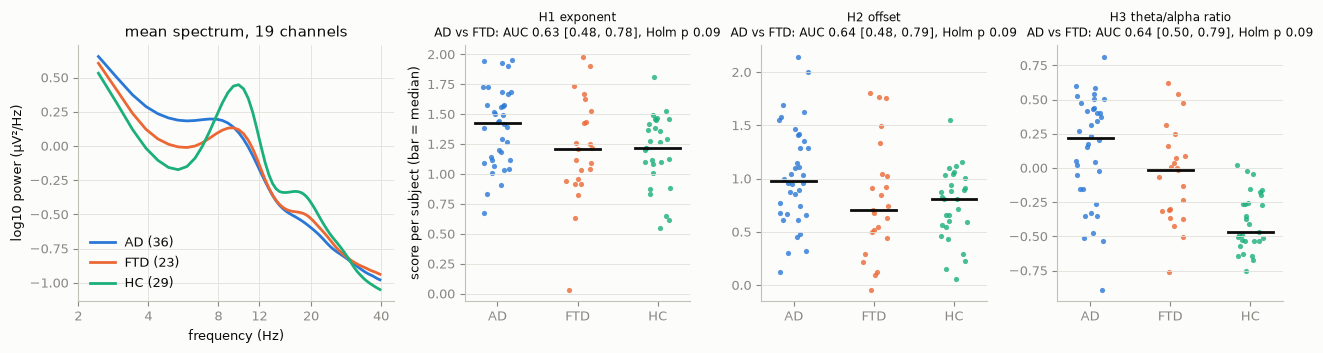

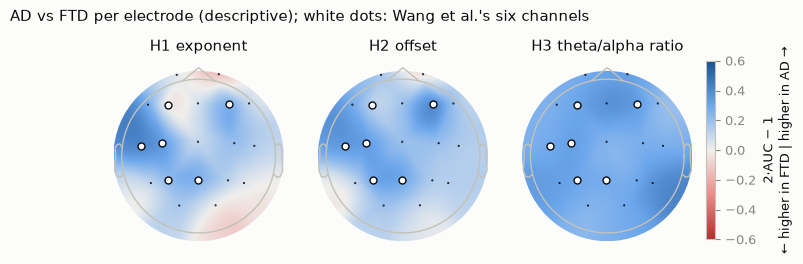

In [7]:
# ===========================================================================
# CELL 7 — FIGURES
# ===========================================================================
ORDER = ["AD", "FTD", "HC"]
g_of = subj.group.to_numpy()
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[1.4, 1, 1, 1]))

ax = axes[0]
band = (FREQS >= FIT_RANGE[0]) & (FREQS <= FIT_RANGE[1])
for g in ORDER:
    ax.plot(FREQS[band], np.log10(PSD[g_of == g][..., band]).mean(axis=(0, 1)), color=GROUP_COLOR[g],
            label=f"{g} ({(g_of == g).sum()})")
ax.set_xscale("log")
ax.set_xticks([2, 4, 8, 12, 20, 40], ["2", "4", "8", "12", "20", "40"])
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set(xlabel="frequency (Hz)", ylabel="log10 power (µV²/Hz)", title="mean spectrum, 19 channels")
ax.legend(loc="lower left")

jitter = np.random.default_rng(0).uniform(-0.18, 0.18, len(subj))
for ax, (name, col), t in zip(axes[1:], HYPOTHESES.items(), TESTS.itertuples()):
    v = SCORES[col].to_numpy()
    for i, g in enumerate(ORDER):
        m = g_of == g
        ax.scatter(i + jitter[m], v[m], s=14, color=GROUP_COLOR[g], alpha=0.8, linewidths=0)
        ax.plot([i - 0.28, i + 0.28], [np.nanmedian(v[m])] * 2, color=INK, lw=2)
    ax.set_xticks(range(3), ORDER)
    ax.grid(axis="x", visible=False)
    ax.set_title(f"{name}\nAD vs FTD: AUC {t.auc:.2f} [{t.ci_low:.2f}, {t.ci_high:.2f}], Holm p {t.p_holm:.2f}",
                 fontsize=8.5)
axes[1].set_ylabel("score per subject (bar = median)")
fig.tight_layout()
fig.savefig(RESULT_DIR / "aperiodic.png", dpi=200, bbox_inches="tight")
plt.show()

info = mne.create_info(CHANNELS, SFREQ, "eeg")
info.set_montage("standard_1020")
mask = np.isin(CHANNELS, WANG_CHANNELS)
fig, axes = plt.subplots(1, 3, figsize=(9, 2.9))
for ax, (name, col) in zip(axes, HYPOTHESES.items()):
    v = 2 * PER_CHANNEL.set_index("channel").loc[CHANNELS, col].to_numpy() - 1
    im, _ = mne.viz.plot_topomap(v, info, axes=ax, cmap=DIVERGING.reversed(), vlim=(-0.6, 0.6), show=False,
                                 contours=0, mask=mask, mask_params=dict(marker="o", markerfacecolor="white",
                                                                          markeredgecolor=INK, markersize=5))
    ax.set_title(name)
cb = fig.colorbar(im, ax=axes, shrink=0.8, pad=0.02)
cb.set_label("2·AUC − 1\n← higher in FTD | higher in AD →")
fig.suptitle("AD vs FTD per electrode (descriptive); white dots: Wang et al.'s six channels", x=0.01, ha="left")
fig.savefig(RESULT_DIR / "topomaps.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
# ===========================================================================
# CELL 8 — SAVE results/aperiodic/
# ===========================================================================
scores = SCORES.join(SCORES_2S[["exponent", "offset"]].add_suffix("_2s")) \
               .join(SCORES_ALL[["exponent", "offset"]].add_suffix("_no_r2_filter"))
scores.insert(0, "group", subj.group)
scores.to_csv(RESULT_DIR / "subject_scores.csv", float_format="%.6f")
pd.concat([FITS.assign(window="0.5 s Hamming (Wang)"), FITS_2S.assign(window="2 s Hann")]) \
  .to_csv(RESULT_DIR / "channel_fits.csv", index=False, float_format="%.6f")
TESTS.to_csv(RESULT_DIR / "tests.csv", index=False, float_format="%.6f")
S2 = pd.DataFrame([dict(hypothesis="H1-H3 together", variant=f"L2 logistic regression, {N_REPEATS} x {N_FOLDS}-fold CV",
                        auc=AUC_CV, ci_low=np.percentile(BOOT_CV, 2.5), ci_high=np.percentile(BOOT_CV, 97.5),
                        bal_acc=BAL_CV, null_mean=NULL_CV.mean(), null_low=np.percentile(NULL_CV, 2.5),
                        null_high=np.percentile(NULL_CV, 97.5), p_one_sided=P_CV)])
pd.concat([ADJUSTED.assign(analysis="S1 adjusted for MMSE, age, sex"), S2.assign(analysis="S2 classifier"),
           CONTROLS.assign(analysis="S3 positive control"), ROBUST.assign(analysis="S4-S5 robustness"),
           MUSCLE.assign(analysis="S6 muscle (post hoc)")],
          ignore_index=True).to_csv(RESULT_DIR / "secondary.csv", index=False, float_format="%.6f")
PER_CHANNEL.to_csv(RESULT_DIR / "per_channel.csv", index=False, float_format="%.6f")

for f in sorted(RESULT_DIR.iterdir()):
    print(f"{f.name:22s}{f.stat().st_size / 1024:8.1f} KB")

aperiodic.png            183.7 KB
channel_fits.csv         215.3 KB
per_channel.csv            0.6 KB
protocol.json              2.5 KB
secondary.csv              2.4 KB
subject_scores.csv         6.9 KB
tests.csv                  0.4 KB
topomaps.png             176.7 KB


---
## Reading the result

**The pre-registered answer is: not supported. All three scores still point the
way Wang et al. predicted.**

| 36 AD vs 23 FTD | AUC = P(AD > FTD) [95 % CI] | p, one-sided | Holm p |
|---|---|---|---|
| H1 aperiodic exponent | 0.632 [0.481, 0.779] | 0.048 | 0.088 |
| H2 aperiodic offset | 0.640 [0.482, 0.785] | 0.036 | 0.088 |
| H3 theta/alpha ratio | 0.644 [0.498, 0.785] | 0.029 | 0.088 |

- **Each test passes alone; none survives correction.** With 23 FTD patients, a
  one-sided p < 0.05 needs an AUC of about 0.63, and these sit right at that edge.
  The power analysis made this a coin toss beforehand: about 50 % to detect a
  true AUC of 0.65.
- **Its own controls match Wang et al.'s pattern.** The exponent separates AD from
  healthy controls (AUC 0.664, p = 0.012), but FTD is indistinguishable from healthy
  controls (0.498). Theta/alpha is raised in both dementias (0.868 and 0.798),
  more so in AD.
- **Much of it travels with severity.** Once MMSE, age and sex are known, the
  exponent and the offset add nothing (p = 0.44 and 0.205). Theta/alpha still adds
  a little (p = 0.046, uncorrected). The AD patients here are more advanced, so
  part of the "AD vs FTD" difference is plausibly "more vs less advanced".
- **It is not muscle, and not the window.** Failed fits and 30–40 Hz power do not
  differ between the groups (AUC 0.455 and 0.522). Restricting to well-fitted
  subjects leaves 0.63 and 0.66. With unbiased 2 s windows the scores reach 0.615
  and 0.633.
- **For one patient, it is still not usable.** A classifier on the three scores
  reaches AUC 0.616 [0.469, 0.759] and balanced accuracy 0.641. That is the best
  EEG result in this AD-vs-FTD study (band power: 0.540), but it is not
  distinguishable from chance (p = 0.076; shuffled labels reach up to 0.66).

**What this does and does not show.**
- **It shows** that on the same 59 people, under an honest protocol, the AD-vs-FTD
  difference Wang et al. reported has the direction they found and nearly their
  size (AUC 0.63–0.64, against their 0.66, which leaked through SMOTE).
- **It does not make this an AD-vs-FTD marker.** The result fails correction,
  overlaps with disease severity, and comes from the same subjects as the
  original claim. That makes it a reproduction, not a replication.
- **Settling it** would take about 47 or more new FTD patients for 80 % power at
  AUC 0.65.
- **A methods finding for anyone using this dataset.** Wang et al.'s 0.5 s
  window overestimates steep exponents (1/f^1.5 → 1.74), because low-frequency
  power leaks into the fit. In dementia, that low-frequency power is delta.